# 16. 파생 변수 5종 계속 — 방향 뒤집힘(심슨의 역설) 고치기
15에서 파생 5종 PVC는 방향을 거꾸로 배웠다(Stellantis N.V. AUROC 0.31). 진단: 편차·변화량 특징은 **날짜 안에서는 클수록 위험**(AUROC 0.68~0.74)인데
**날짜 평균은 날짜 불량률과 음의 상관**(직전 변화 I/F −0.82)이다. 날짜별 개수만 보는 학습은 날짜 사이 관계를 따라간다.
사전 지정 후보(두 데이터 동일, 입력은 여전히 파생 5종 9개뿐):
- **D1** 날짜 안 표준화(daystd) + PVC MLP — 날짜 사이 교란 제거
- **D2** 날짜 안 이탈 크기 |강건 z|(absz) + PVC MLP — 1장 정의 "기준에서 벗어날수록 위험"
- **D3** absz + 단조 개수 모델(가중치 ≥ 0) — 방향을 사전지식으로 고정해 뒤집힘을 막음
- **D5** (17 이후 추가) 규칙 사전지식 모델: logit = b + a·이탈 크기 합 + w·x, a ≥ 0, w ≥ 0이며 L2로 0 쪽으로 당김
진단에 Stellantis N.V. 정답을 썼으므로 이 후보들은 탐색 결과로 표시한다. 우선 5시드로 거르고, 좋은 후보만 10시드로 늘린다.

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import br
from br import spec as S, budget as B, plot as P
from wl.metrics import inclusion_prob
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
CANDS = {"D1 날짜안표준화+PVC": ("derived5_daystd", "PVC MLP"), "D2 이탈크기+PVC": ("derived5_absz", "PVC MLP"),
         "D3 이탈크기+단조": ("derived5_absz", "단조 개수 모델"), "D5 규칙사전지식": ("derived5_absz", "규칙 사전지식 모델")}
SEEDS = range(5)
cache = br.RES / "derived5_fix_scores.pkl"
sc = pd.read_pickle(cache) if cache.exists() else pd.DataFrame(columns=["cand", "data", "seed", "row", "score", "prob"])
done = set(map(tuple, sc[["cand", "data", "seed"]].drop_duplicates().values))
LOAD = {}
t0 = time.time()
for s in SEEDS:
    for cand, (fs, model) in CANDS.items():
        for ds in ("polito", "kamp"):
            if (cand, ds, s) in done or time.time() - t0 > 270:
                continue
            if (fs, ds) not in LOAD:
                LOAD[(fs, ds)] = (S.load_polito if ds == "polito" else S.load_kamp)(fs)
            X, day, cnt, y, blk = LOAD[(fs, ds)]
            t = time.time(); score, prob = S.lodo(model, X, day, cnt, s)
            sc = pd.concat([sc, pd.DataFrame({"cand": cand, "data": ds, "seed": s, "row": np.arange(len(day)), "score": score, "prob": prob})], ignore_index=True)
            sc.to_pickle(cache)
            print(f"{cand:18s} {ds:6s} seed={s}  {time.time()-t:5.1f}초", flush=True)
n_done = len(set(map(tuple, sc[["cand", "data", "seed"]].drop_duplicates().values)))
print(f"진행: {n_done}/{len(CANDS)*2*len(SEEDS)}")
COMPLETE = n_done == len(CANDS) * 2 * len(SEEDS)

D5 규칙사전지식          polito seed=0   34.3초


D5 규칙사전지식          kamp   seed=0   16.3초


D5 규칙사전지식          polito seed=1   33.4초


D5 규칙사전지식          kamp   seed=1   16.3초


D5 규칙사전지식          polito seed=2   33.4초


D5 규칙사전지식          kamp   seed=2   16.3초


D5 규칙사전지식          polito seed=3   33.3초


D5 규칙사전지식          kamp   seed=3   16.3초


D5 규칙사전지식          polito seed=4   34.2초


D5 규칙사전지식          kamp   seed=4   16.4초


진행: 40/40


In [2]:
if COMPLETE:
    X, day, cnt, y, _ = S.load_polito()
    body = wldata.load_polito().body.values
    rng = np.random.default_rng(7); ub = np.unique(body)
    Wb = np.stack([np.bincount(d_, minlength=len(ub)) for d_ in rng.integers(0, len(ub), (5000, len(ub)))])[:, np.searchsorted(ub, body)]
    ud, gi = np.unique(day, return_inverse=True); n = np.bincount(gi)
    def ms(src, key, val, ds="polito", seeds=SEEDS):
        g = src[(src[key] == val) & (src.data == ds) & src.seed.isin(seeds)]
        return np.mean([gg.sort_values("row").score.values.astype(float) for _, gg in g.groupby("seed")], 0)
    RAW = pd.read_pickle(br.RES / "same_model_scores.pkl"); D5 = pd.read_pickle(br.RES / "same_model_scores_derived5.pkl")
    SCORES = {"raw (제공4+파생3)": ms(RAW, "model", "PVC MLP"), "파생5종 원래(15)": ms(D5, "model", "PVC MLP"),
              **{c: ms(sc, "cand", c) for c in CANDS}}
    def ci(a): return f"{np.mean(a):+.3f} [{np.quantile(a,.025):+.3f}, {np.quantile(a,.975):+.3f}]"
    rows = []
    for nm, s_ in SCORES.items():
        r = {"사양": nm, "AUROC": round(roc_auc_score(y, s_), 3)}
        for b in (.05, .1, .2, .3):
            k = np.ceil(b * n - 1e-9); p_ = inclusion_prob(s_, k, gi); pr = (k / n)[gi]
            r[f"{int(b*100)}%"] = round((p_ * y).sum() / y.sum(), 3)
            if b == .1:
                r["10% 무작위 대비 [95%]"] = ci((Wb @ ((p_ - pr) * y)) / (Wb @ y))
        rows.append(r)
    rows.append({"사양": "무작위", **{f"{int(b*100)}%": round((np.ceil(b * n - 1e-9) / n * np.bincount(gi, weights=y)).sum() / y.sum(), 3) for b in (.05, .1, .2, .3)}})
    res = pd.DataFrame(rows); res.to_csv(br.RES / "derived5_fix_polito.csv", index=False, encoding="utf-8-sig"); display(res)

,사양,AUROC,5%,10%,10% 무작위 대비 [95%],20%,30%
0,raw (제공4+파생3),0.725,0.139,0.291,"+0.176 [+0.062, +0.267]",0.494,0.658
1,파생5종 원래(15),0.302,0.038,0.076,"-0.033 [-0.083, +0.021]",0.114,0.127
2,D1 날짜안표준화+PVC,0.471,0.051,0.101,"-0.005 [-0.058, +0.058]",0.228,0.304
3,D2 이탈크기+PVC,0.433,0.076,0.114,"+0.005 [-0.049, +0.065]",0.177,0.253
4,D3 이탈크기+단조,0.573,0.076,0.114,"+0.002 [-0.065, +0.073]",0.241,0.354
5,D5 규칙사전지식,0.613,0.076,0.127,"+0.016 [-0.051, +0.079]",0.291,0.443
6,무작위,NaN,0.062,0.108,NaN,0.202,0.309


In [3]:
if COMPLETE:
    # KAMP 개수 MAE (5시드 평균 확률 합) — 고정 불량률 2.19
    Xk, kday, kcnt, _, kblk = S.load_kamp()
    rows = []
    for cand in CANDS:
        g = sc[(sc.cand == cand) & (sc.data == "kamp")]
        p_ = np.mean([gg.sort_values("row").prob.values.astype(float) for _, gg in g.groupby("seed")], 0); ok = ~np.isnan(p_)
        pr = pd.Series(p_[ok]).groupby(kday[ok]).sum()
        rows.append({"사양": cand, "KAMP MAE": round((pr - kcnt.loc[pr.index]).abs().mean(), 2), "추정 합계": round(pr.sum(), 1), "실제 합계": kcnt.loc[pr.index].sum()})
    display(pd.DataFrame(rows))

,사양,KAMP MAE,추정 합계,실제 합계
0,D1 날짜안표준화+PVC,2.20,36.0,39.0
1,D2 이탈크기+PVC,3.60,45.9,39.0
2,D3 이탈크기+단조,2.78,41.5,39.0
3,D5 규칙사전지식,2.87,41.4,39.0


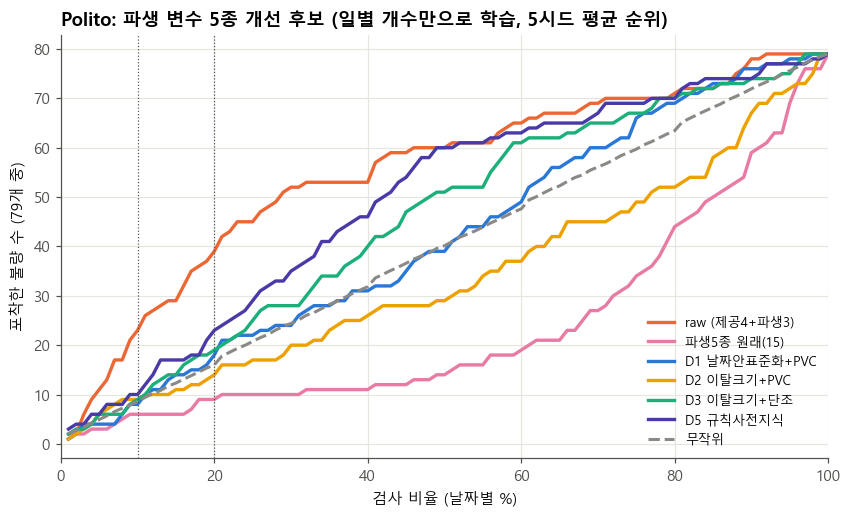

In [4]:
if COMPLETE:
    fig, ax = plt.subplots(figsize=(9, 5))
    bb = B.BUDGETS
    cols = {"raw (제공4+파생3)": P.PAL[1], "파생5종 원래(15)": P.PAL[4], "D1 날짜안표준화+PVC": P.PAL[0], "D2 이탈크기+PVC": P.PAL[3], "D3 이탈크기+단조": P.PAL[2], "D5 규칙사전지식": P.PAL[6]}
    for nm, s_ in SCORES.items():
        ax.plot(bb * 100, [(inclusion_prob(s_, np.ceil(b * n - 1e-9), gi) * y).sum() for b in bb], color=cols[nm], lw=2.2, label=nm)
    ax.plot(bb * 100, [(np.ceil(b * n - 1e-9) / n * np.bincount(gi, weights=y)).sum() for b in bb], "--", color=P.GRAY, label="무작위")
    for b in (10, 20): ax.axvline(b, color=P.INK2, lw=.8, ls=":")
    ax.set_xlim(0, 100); ax.set_xlabel("검사 비율 (날짜별 %)"); ax.set_ylabel("포착한 불량 수 (79개 중)")
    ax.set_title("Stellantis N.V.: 파생 변수 5종 개선 후보 (일별 개수만으로 학습, 5시드 평균 순위)", loc="left", fontweight="bold"); ax.legend(fontsize=8.5, loc="lower right")
    P.save(fig, "14_derived5_fix"); plt.show()